,Junction,Vehicles per Hour,Green Time (seconds)
4,Junction 5,132.9,25.5
1,Junction 2,123.1,24.7
0,Junction 1,112.6,23.9
3,Junction 4,111.0,23.7
2,Junction 3,92.4,22.3


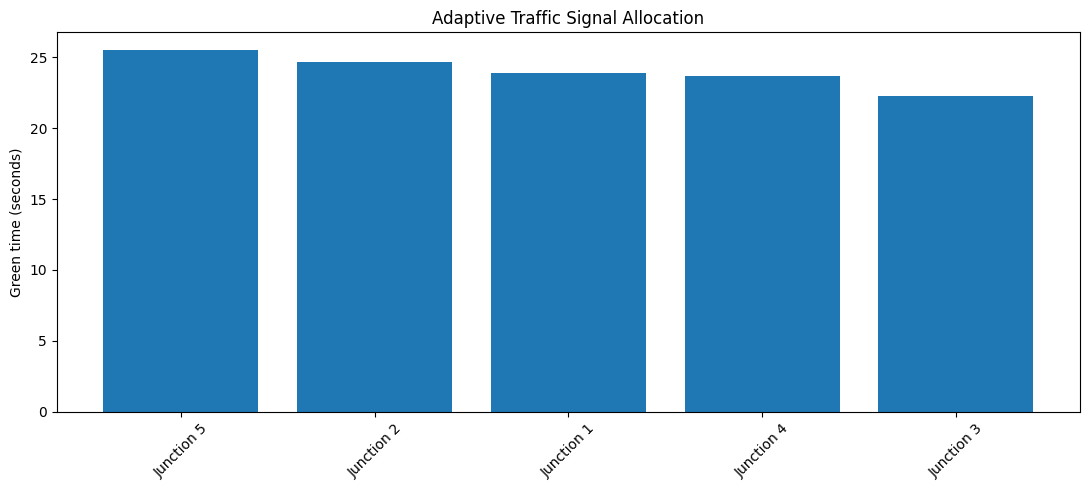

AMBULANCE DETECTED!
Priority junction: 5
Recommended green signal: 90 seconds


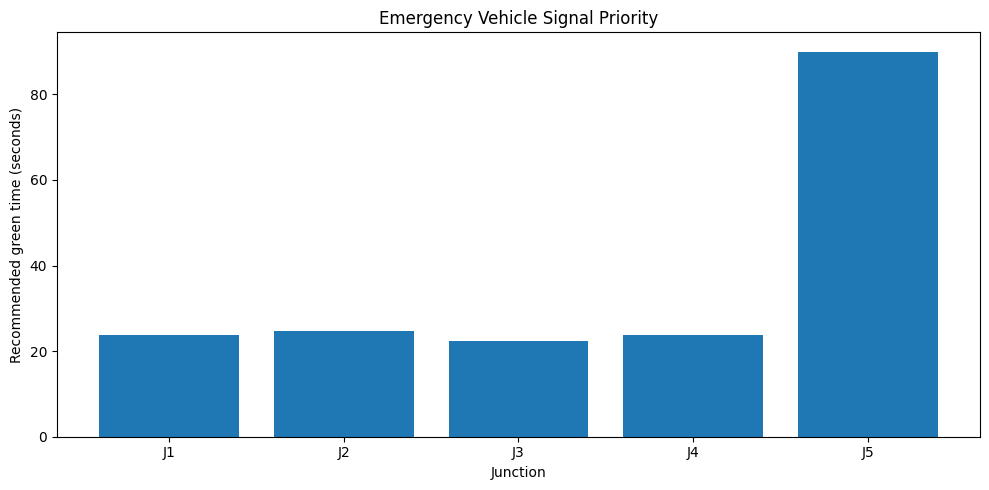

,Junction,Predicted Vehicles,Status
3,Junction 4,123.6,Moderate
4,Junction 5,123.0,Moderate
0,Junction 1,117.1,Moderate
1,Junction 2,115.9,Moderate
2,Junction 3,107.0,Moderate


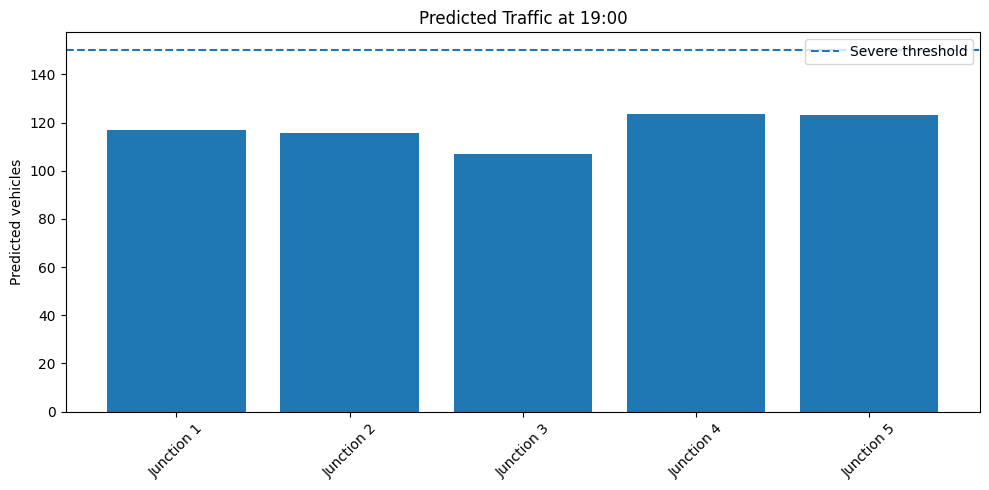

⚠️ WARNING: Junction 1 has moderate traffic.
⚠️ WARNING: Junction 2 has moderate traffic.
⚠️ WARNING: Junction 3 has moderate traffic.
⚠️ WARNING: Junction 4 has moderate traffic.
⚠️ WARNING: Junction 5 has moderate traffic.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Create synthetic traffic data (days, junctions, hours)
np.random.seed(42)
junctions = 5
days = 7
hours = 24
traffic = np.random.randint(20, 200, size=(days, junctions, hours))

current_hour = 18
min_green = 15
max_green = 90
total_cycle = 120

current_traffic = traffic[:, :, current_hour].mean(axis=0)

# Allocate green time according to traffic demand
weights = current_traffic / current_traffic.sum()
green_times = min_green + weights * (
    total_cycle - min_green * len(current_traffic)
)

green_times = np.clip(green_times, min_green, max_green)

signals = pd.DataFrame({
    "Junction": [f"Junction {i+1}" for i in range(junctions)],
    "Vehicles per Hour": current_traffic.round(1),
    "Green Time (seconds)": green_times.round(1)
})

signals = signals.sort_values(
    "Vehicles per Hour", ascending=False
)

display(signals)

plt.figure(figsize=(11, 5))
plt.bar(signals["Junction"], signals["Green Time (seconds)"])
plt.title("Adaptive Traffic Signal Allocation")
plt.ylabel("Green time (seconds)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

ambulance_junction = 4  # Junction 5 (zero-based index)

priority_times = green_times.copy()

# Simulate emergency priority
priority_times[ambulance_junction] = max_green

print("AMBULANCE DETECTED!")
print(f"Priority junction: {ambulance_junction + 1}")
print("Recommended green signal:", max_green, "seconds")

plt.figure(figsize=(10, 5))
plt.bar(
    [f"J{i+1}" for i in range(junctions)],
    priority_times
)
plt.title("Emergency Vehicle Signal Priority")
plt.xlabel("Junction")
plt.ylabel("Recommended green time (seconds)")
plt.tight_layout()
plt.show()

next_hour = (current_hour + 1) % 24

predicted_traffic = traffic[:, :, next_hour].mean(axis=0)

prediction = pd.DataFrame({
    "Junction": [f"Junction {i+1}" for i in range(junctions)],
    "Predicted Vehicles": predicted_traffic.round(1)
})

prediction["Status"] = np.where(
    prediction["Predicted Vehicles"] >= 150,
    "Severe",
    np.where(
        prediction["Predicted Vehicles"] >= 100,
        "Moderate",
        "Normal"
    )
)

display(prediction.sort_values(
    "Predicted Vehicles", ascending=False
))

plt.figure(figsize=(10, 5))
plt.bar(
    prediction["Junction"],
    prediction["Predicted Vehicles"]
)
plt.axhline(150, linestyle="--", label="Severe threshold")
plt.title(f"Predicted Traffic at {next_hour:02d}:00")
plt.ylabel("Predicted vehicles")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

for _, row in prediction.iterrows():
    if row["Status"] == "Severe":
        print(f"🚨 ALERT: {row['Junction']} has severe predicted traffic!")
    elif row["Status"] == "Moderate":
        print(f"⚠️ WARNING: {row['Junction']} has moderate traffic.")
    else:
        print(f"✅ {row['Junction']} traffic is normal.")